# 02 Incidents: salience gap (H1) and travel window (H2)

Confirmatory tests of H1 and H2 as fixed in `docs/preregistration.md` (tag `prereg-v1`, with the amendments in section 8). Data: the incident register `data/processed/incidents.csv` (96 incidents, 2011 to 2026; source IDs per incident) and the NYSC calendar `data/processed/nysc_calendar.csv` [A11]. Data cutoff: 5 October 2026, the date of the logged archive search [A15]. All tests use alpha = 0.05.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nysc_safety import camp_calendar, figures, paths, salience
from nysc_safety.travel_window import H2_STAGES, h2_sample, ids_citing, travel_window_test

figures.style()
CUTOFF = date(2026, 10, 5)  # [A15]
START = date(2010, 1, 1)
TABLES = paths.ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

incidents = pd.read_csv(paths.DATA_PROCESSED / "incidents.csv")
incident_sources = figures.id_ranges(s for ids in incidents["source_ids"] for s in ids.split(";"))
print(f"{len(incidents)} incidents, {incidents['event_date'].min()} to {incidents['event_date'].max()}")
print(f"Incident source IDs: {incident_sources}")

96 incidents, 2011-04-08 to 2026-10-01
Incident source IDs: S18-S20, S22-S146, S148-S153


## H1: salience gap

Articles per incident (`n_articles`: distinct articles in Premium Times, Daily Trust and Channels Television within 30 days of the event; pre-registration amendment of 2026-10-05) are compared between incidents in the North West and North East and incidents in the South West, South East and South South with a one-sided Mann-Whitney U test. North Central incidents are in neither group [A03]. The effect size is the rank-biserial correlation (negative when northern incidents have fewer articles), with a bootstrap 95% interval (10,000 resamples).

In [2]:
north, south = salience.zone_groups(incidents)
h1 = salience.mann_whitney(north, south)
pd.Series(h1).round(4).to_frame("value")

,value
n_north,23.0000
n_south,46.0000
median_north,1.0000
median_south,1.0000
mean_north,1.8261
mean_south,1.7609
u_north,538.0000
p_value,0.5529
rank_biserial,0.0170
rb_ci_lower,-0.2581


In [3]:
incidents.groupby("zone")["n_articles"].agg(["count", "median", "mean", "sum"]).round(2)

,count,median,mean,sum
zone,,,,
North Central,27,2.0,2.78,75
North East,8,1.0,0.88,7
North West,15,2.0,2.33,35
South East,11,2.0,2.82,31
South South,27,1.0,1.33,36
South West,8,1.5,1.75,14


Supporting measure: Spearman correlation between each state's share of incidents and its share of articles. The main version uses states with at least one incident; the version over all 37 states is shown for comparison (states with no incident have no articles, which adds tied zero pairs).

In [4]:
shares = salience.state_shares(incidents)
with_incidents = shares[shares["incidents"] > 0]
h1_rho = salience.spearman(with_incidents["incident_share"], with_incidents["article_share"])
h1_rho_all = salience.spearman(shares["incident_share"], shares["article_share"])
pd.DataFrame({"states with incidents": h1_rho, "all 37 states": h1_rho_all}).round(3)

,states with incidents,all 37 states
n,32.000,37.000
rho,0.829,0.886
p_value,0.000,0.000
ci_lower,0.670,0.785
ci_upper,0.916,0.942


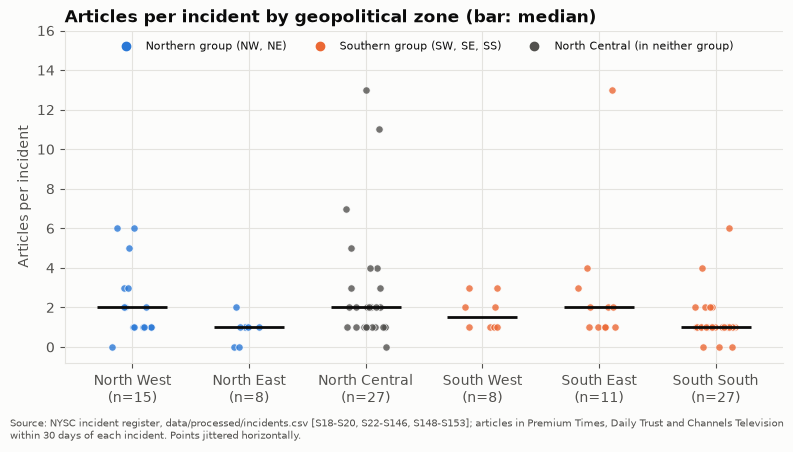

In [5]:
order = ["North West", "North East", "North Central", "South West", "South East", "South South"]
colour = {z: figures.SERIES[0] for z in salience.NORTH} | {z: figures.SERIES[1] for z in salience.SOUTH}
colour["North Central"] = figures.TEXT_SECONDARY
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, zone in enumerate(order):
    values = incidents.loc[incidents["zone"] == zone, "n_articles"]
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(values)), values, s=28, color=colour[zone], alpha=0.8,
               edgecolor="white", linewidth=0.6, zorder=3)
    ax.hlines(values.median(), i - 0.3, i + 0.3, color=figures.TEXT, linewidth=2, zorder=4)
ax.set_xticks(range(len(order)), [f"{z}\n(n={int((incidents['zone'] == z).sum())})" for z in order])
ax.set_ylabel("Articles per incident")
ax.set_title("Articles per incident by geopolitical zone (bar: median)")
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, label=l) for c, l in
           ((figures.SERIES[0], "Northern group (NW, NE)"), (figures.SERIES[1], "Southern group (SW, SE, SS)"),
            (figures.TEXT_SECONDARY, "North Central (in neither group)"))]
ax.set_ylim(-0.8, 16)
ax.legend(handles=handles, loc="upper center", ncol=3, fontsize=8)
figures.save(fig, "h1_articles_per_incident_by_zone",
             f"NYSC incident register, data/processed/incidents.csv [{incident_sources}]; articles in Premium Times, "
             "Daily Trust and Channels Television within 30 days of each incident. Points jittered horizontally.")
plt.show()

### H1 result

Northern incidents (n = 23) and southern incidents (n = 46) have the same median of 1 article per incident (means 1.83 and 1.76). The one-sided Mann-Whitney U test gives U = 538 and p = 0.553, and the rank-biserial correlation is 0.02 (bootstrap 95% interval -0.26 to 0.30). H1 is not supported: in the three fully searched outlets, incidents in the North West and North East did not receive fewer articles than incidents in the southern zones.

The two northern zones differ from each other. The North East has a median of 1 article (8 incidents) and the North West a median of 2 (15 incidents). State shares of articles track state shares of incidents (Spearman rho 0.83, 95% interval 0.67 to 0.92, 32 states with at least one incident).

The test measures coverage of incidents that were reported at all. Incidents never reported in the three outlets are not in the register, so a gap in whether incidents are reported in the first place is outside the reach of this test (`docs/analysis_plan.md`, section 9).

## H2: travel window

The test counts incidents within 7 days either side of any camp-opening or passing-out date and compares their share with the share of calendar days from 1 January 2010 to the cutoff that fall inside such a window, using a one-sided exact binomial test (`nysc_safety.travel_window.travel_window_test`). The main sample is incidents with day-precision dates in the stages `travel_to_camp`, `camp`, `travel_to_ppa` and `passing_out` [A01, A04]. Anchors are all camp-opening and passing-out dates in the calendar, whatever their basis (`reported`, `batch_report`, `derived`) [A11], plus the additional camp-opening date marked `use_extra` in `data/interim/calendar/nysc_dates.csv`.

Sensitivity runs: `personal_travel` included [A04]; reported anchors only [A11]; 2016 to 2026 only; excluding the journeys from camp coded under A05; and, as stated in A07, excluding incidents dated from a weekday only.

In [6]:
calendar = pd.read_csv(paths.DATA_PROCESSED / "nysc_calendar.csv")
for column in ("camp_opening", "camp_closing", "passing_out"):
    calendar[column] = pd.to_datetime(calendar[column]).dt.date
dates = pd.read_csv(paths.DATA_INTERIM / "calendar" / "nysc_dates.csv", dtype=str)
extras = dates[dates["status"] == "use_extra"]
calendar_sources = figures.id_ranges(
    s for ids in dates.loc[dates["status"].isin(["use", "use_extra"]), "source_id"].dropna() for s in ids.split(";")
)
anchors_all = camp_calendar.anchors(calendar, extras)
anchors_reported = camp_calendar.anchors(calendar, extras, bases=("reported",))
print(f"Anchors: {len(anchors_all)} (all bases), {len(anchors_reported)} (reported only)")

in_stages = incidents["lifecycle_stage"].isin(H2_STAGES)
print("Incidents in the H2 stages by date precision:", incidents.loc[in_stages, "date_precision"].value_counts().to_dict())
a05, a07 = ids_citing(incidents, "A05"), ids_citing(incidents, "A07")
print(f"A05 journeys: {sorted(a05)}")
print(f"A07 weekday-dated incidents in the H2 stages: {sorted(a07 & set(incidents.loc[in_stages, 'incident_id']))}")

Anchors: 142 (all bases), 116 (reported only)
Incidents in the H2 stages by date precision: {'day': 21, 'month': 2}
A05 journeys: ['INC0069', 'INC0071', 'INC0081', 'INC0095']
A07 weekday-dated incidents in the H2 stages: ['INC0010', 'INC0044']


In [7]:
runs = {
    "Main": dict(stages=H2_STAGES, anchors=anchors_all, start=START),
    "personal_travel included": dict(stages=H2_STAGES + ("personal_travel",), anchors=anchors_all, start=START),
    "Reported anchors only": dict(stages=H2_STAGES, anchors=anchors_reported, start=START),
    "2016 to 2026 only": dict(stages=H2_STAGES, anchors=anchors_all, start=date(2016, 1, 1)),
    "Excluding A05 journeys": dict(stages=H2_STAGES, anchors=anchors_all, start=START, exclude=a05),
    "Excluding A07 dates": dict(stages=H2_STAGES, anchors=anchors_all, start=START, exclude=a07),
}
rows = {}
for name, run in runs.items():
    sample = h2_sample(incidents, run["stages"], run.get("exclude", frozenset()))
    rows[name] = travel_window_test(sample["event_day"], run["anchors"], run["start"], CUTOFF)
h2 = pd.DataFrame(rows).T
h2["ratio"] = h2["observed_share"] / h2["expected_share"]
h2.round(3)

,n_events,in_window,observed_share,share_ci_lower,share_ci_upper,expected_share,p_value,ratio
Main,21.0,11.0,0.524,0.298,0.743,0.306,0.030,1.714
personal_travel included,36.0,18.0,0.500,0.329,0.671,0.306,0.011,1.636
Reported anchors only,21.0,10.0,0.476,0.257,0.702,0.270,0.034,1.767
2016 to 2026 only,20.0,11.0,0.550,0.315,0.769,0.362,0.067,1.519
Excluding A05 journeys,18.0,10.0,0.556,0.308,0.785,0.306,0.024,1.818
Excluding A07 dates,19.0,11.0,0.579,0.335,0.797,0.306,0.012,1.894


In [8]:
window = {d for a in anchors_all for d in pd.date_range(a - pd.Timedelta(days=7), a + pd.Timedelta(days=7)).date}
main_sample = h2_sample(incidents)
main_sample = main_sample.assign(in_window=main_sample["event_day"].isin(window))
main_sample[["incident_id", "event_date", "state", "lifecycle_stage", "harm_type", "in_window"]]

,incident_id,event_date,state,lifecycle_stage,harm_type,in_window
9,INC0010,2014-03-23,Anambra,camp,physical_assault,False
30,INC0031,2018-08-13,Ogun,travel_to_ppa,road_crash,False
35,INC0036,2018-12-07,Katsina,travel_to_ppa,road_crash,True
41,INC0042,2019-03-28,Kano,travel_to_camp,robbery,True
43,INC0044,2019-07-08,Taraba,travel_to_ppa,road_crash,False
47,INC0048,2019-11-29,Edo,travel_to_ppa,road_crash,True
53,INC0054,2020-03-09,Zamfara,travel_to_camp,kidnapping,True
56,INC0057,2020-12-22,Kaduna,travel_to_ppa,killing,False
57,INC0058,2021-07-28,FCT,travel_to_camp,road_crash,False
58,INC0059,2021-10-19,Zamfara,travel_to_camp,kidnapping,True


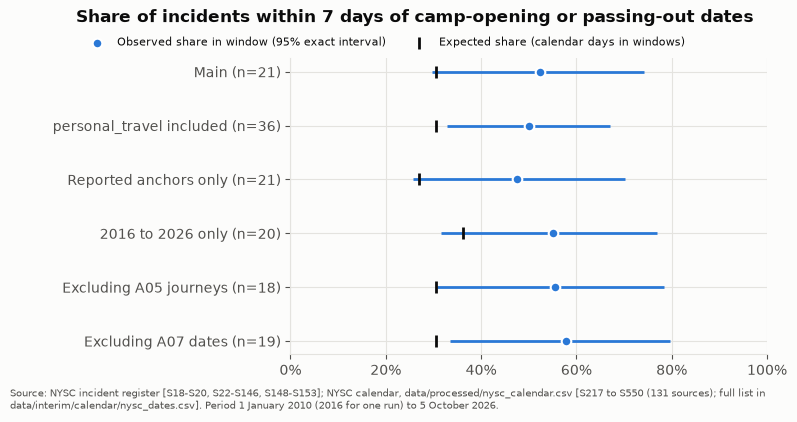

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
names = list(h2.index)[::-1]
y = np.arange(len(names))
obs = h2.loc[names]
ax.hlines(y, obs["share_ci_lower"], obs["share_ci_upper"], color=figures.SERIES[0], linewidth=2, zorder=2)
ax.scatter(obs["observed_share"], y, s=48, color=figures.SERIES[0], edgecolor="white", linewidth=1.5, zorder=3,
           label="Observed share in window (95% exact interval)")
ax.scatter(obs["expected_share"], y, s=70, marker="|", color=figures.TEXT, linewidth=2, zorder=4,
           label="Expected share (calendar days in windows)")
ax.set_yticks(y, [f"{n} (n={int(obs.loc[n, 'n_events'])})" for n in names])
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Share of incidents within 7 days of camp-opening or passing-out dates", loc="left", pad=26, x=-0.45)
ax.legend(loc="lower left", bbox_to_anchor=(-0.45, 1.0), ncol=2, fontsize=8)
figures.save(fig, "h2_travel_window_shares",
             f"NYSC incident register [{incident_sources}]; NYSC calendar, data/processed/nysc_calendar.csv "
             f"[{calendar_sources}; full list in data/interim/calendar/nysc_dates.csv]. Period 1 January 2010 "
             "(2016 for one run) to 5 October 2026.")
plt.show()

In [10]:
h1_out = pd.DataFrame([{"test": "H1 Mann-Whitney U, north vs south", **h1},
                       {"test": "H1 Spearman of state shares (states with incidents)", **h1_rho},
                       {"test": "H1 Spearman of state shares (all 37 states)", **h1_rho_all}])
h1_out.to_csv(TABLES / "h1_results.csv", index=False)
h2.rename_axis("run").reset_index().to_csv(TABLES / "h2_results.csv", index=False)

### H2 result

In the main sample, 11 of 21 day-dated incidents in the travel, camp and passing-out stages (52.4%, exact 95% interval 29.8% to 74.3%) fell within 7 days of a camp-opening or passing-out date. Such windows cover 30.6% of calendar days from 1 January 2010 to 5 October 2026 (ratio 1.71; one-sided exact binomial p = 0.030). H2 is supported at alpha = 0.05. Two incidents in these stages have month-precision dates and are excluded [A01]. No incident in the register is coded `passing_out`, so every incident in the sample is a journey to camp, an incident in camp or a journey from camp.

The result holds with `personal_travel` included (18 of 36, p = 0.011), with reported anchors only (10 of 21 against 27.0%, p = 0.034), without the four A05 journeys (p = 0.024) and without the two A07 weekday-dated incidents (p = 0.012). Restricted to 2016 to 2026, the share is 55.0% (11 of 20) against 36.2% expected, with p = 0.067, which is not significant at 0.05. The expected share is higher in that period because the calendar has 8 to 12 anchor dates a year from 2017, against 3 to 6 before 2016, when batches ran in one stream.

The sample is small, and the interval for the observed share is wide in every run (about 30% to 75% in the main run). Anchors before 2016 rest largely on Low-reliability sources and include derived dates [A11].

## Summary

| Hypothesis | Test | Result | Decision |
|------------|------|--------|----------|
| H1 | One-sided Mann-Whitney U, articles per incident, NW and NE against SW, SE and SS | Medians 1 and 1; U = 538, p = 0.553; rank-biserial 0.02 (95% interval -0.26 to 0.30) | Not supported |
| H2 | One-sided exact binomial, incidents within 7 days of camp-opening or passing-out dates | 11 of 21 (52.4%) against 30.6% expected; p = 0.030; ratio 1.71 | Supported; holds in four of five sensitivity runs, p = 0.067 for 2016 to 2026 only |

Results are saved to `reports/tables/h1_results.csv` and `reports/tables/h2_results.csv`, and charts to `reports/figures/`. The data cutoff [A15] was fixed before the tests were run.